# DSCI 552 — Homework 5

**Ellie He**

In [1]:
import os
os.environ['OMP_NUM_THREADS'] = '1'
os.environ['OPENBLAS_NUM_THREADS'] = '1'
os.environ['MKL_NUM_THREADS'] = '1'
from pathlib import Path
import re, sys, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display, Markdown
from sklearn.base import clone
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.model_selection import StratifiedKFold, KFold, GridSearchCV, cross_val_score, cross_val_predict
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.decomposition import PCA
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score, accuracy_score
from xgboost import XGBRegressor
from threadpoolctl import threadpool_limits
thread_limit = threadpool_limits(limits=1)
SEED = 42
DATA = Path('data') if Path('data').exists() else Path('../data')
pd.set_option('display.max_rows', 150)
pd.set_option('display.max_colwidth', 80)
sns.set_theme(style='whitegrid', context='notebook')
import sklearn, xgboost
print('Python:', sys.version.split()[0], '| sklearn:', sklearn.__version__, '| XGBoost:', xgboost.__version__)

Python: 3.13.18 | sklearn: 1.8.0 | XGBoost: 3.4.1


## 1. Decision Trees as Interpretable Models
### 1(a). Data and Label Encoding
The dataset contains 120 observations and six predictors. Label powerset encoding combines bladder inflammation and nephritis into four joint outcomes: B0_N0, B0_N1, B1_N0, and B1_N1. A value of 1 indicates the disease is present; 0 indicates it is absent.

In [2]:
feature_names = ['Temperature', 'Nausea', 'Lumbar pain', 'Urine pushing', 'Micturition pain', 'Urethral burning']
diagnosis = pd.read_csv(DATA/'diagnosis.data', sep='\t', encoding='utf-16', decimal=',', header=None,
                        names=feature_names + ['Bladder inflammation', 'Nephritis'])
X_diag = diagnosis[feature_names].copy()
for col in feature_names[1:]:
    X_diag[col] = X_diag[col].map({'no':0, 'yes':1})
y_diag = diagnosis['Bladder inflammation'].map({'no':'B0','yes':'B1'}) + '_' + diagnosis['Nephritis'].map({'no':'N0','yes':'N1'})
assert X_diag.shape == (120,6) and not X_diag.isna().any().any()
print('B = bladder inflammation; N = nephritis; 0 = no, 1 = yes.')
display(y_diag.value_counts().rename_axis('Joint outcome').to_frame('Count').sort_index())
display(diagnosis.head())

B = bladder inflammation; N = nephritis; 0 = no, 1 = yes.


,Count
Joint outcome,
B0_N0,30
B0_N1,31
B1_N0,40
B1_N1,19


,Temperature,Nausea,Lumbar pain,Urine pushing,Micturition pain,Urethral burning,Bladder inflammation,Nephritis
0,35.5,no,yes,no,no,no,no,no
1,35.9,no,no,yes,yes,yes,yes,no
2,35.9,no,yes,no,no,no,no,no
3,36.0,no,no,yes,yes,yes,yes,no
4,36.0,no,yes,no,no,no,no,no


### 1(b). Full Decision Tree
The full tree has six leaves and depth four. Training accuracy is 100%.

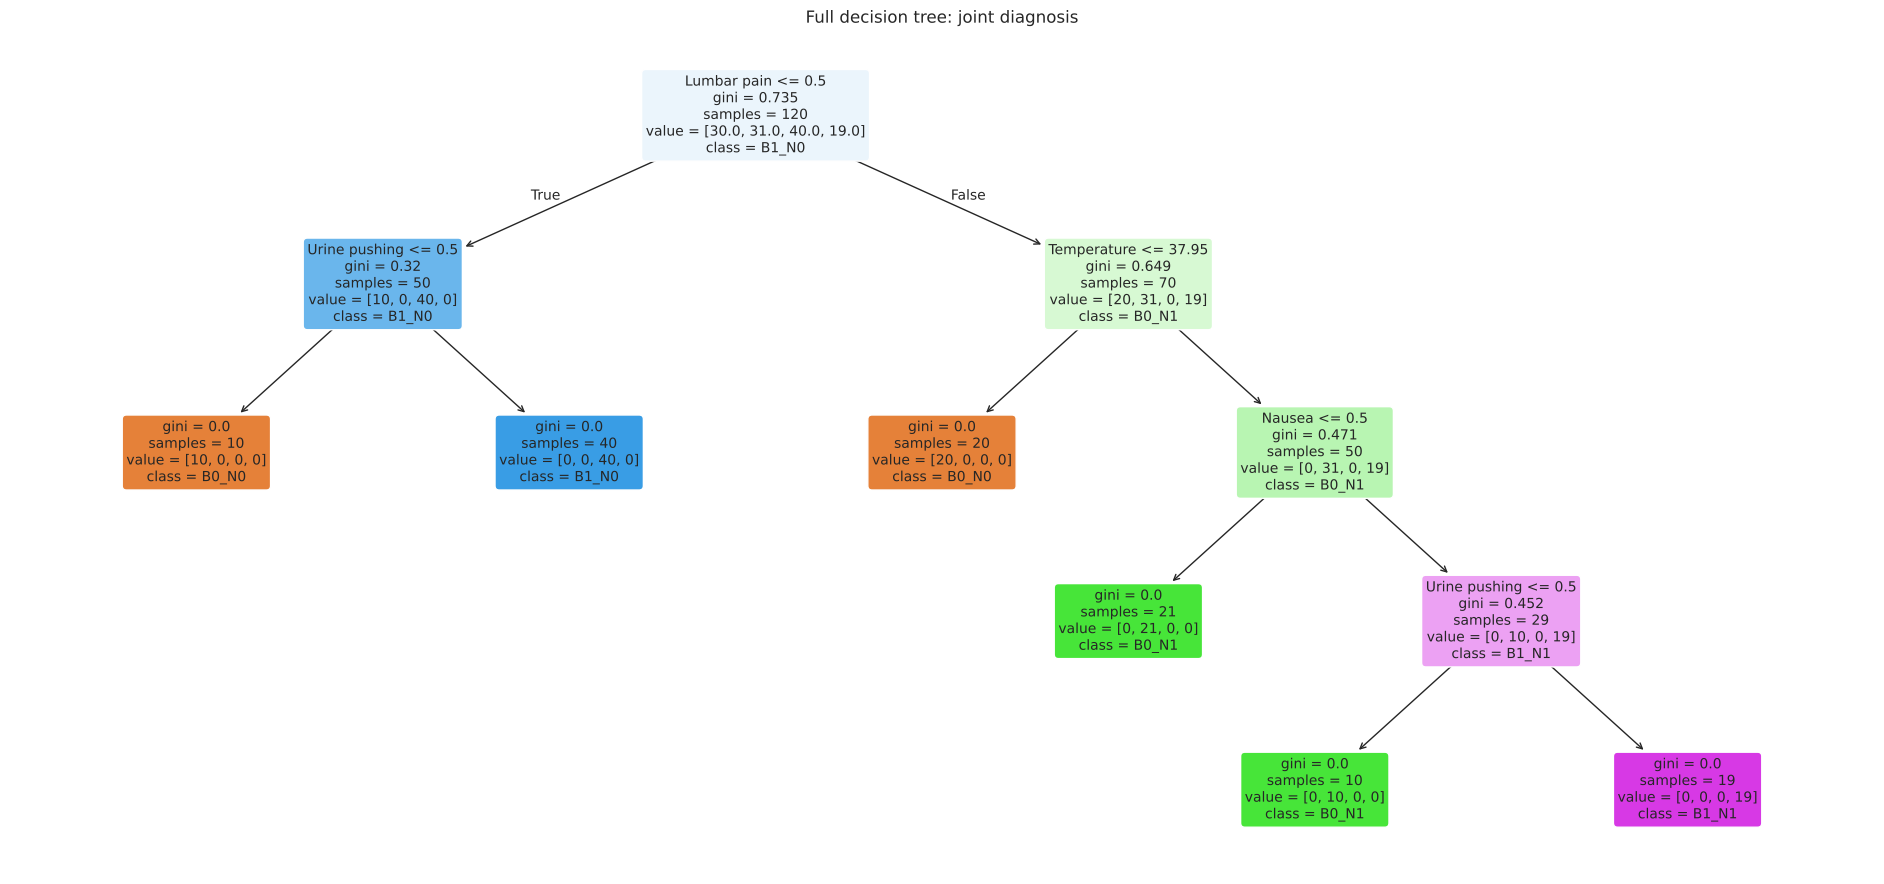

Depth: 4; leaves: 6; training accuracy: 1.0000


In [3]:
full_tree = DecisionTreeClassifier(random_state=SEED).fit(X_diag, y_diag)
fig, ax = plt.subplots(figsize=(19,9))
plot_tree(full_tree, feature_names=feature_names, class_names=full_tree.classes_, filled=True, rounded=True, fontsize=10, ax=ax)
ax.set_title('Full decision tree: joint diagnosis')
plt.tight_layout(); plt.show()
print(f'Depth: {full_tree.get_depth()}; leaves: {full_tree.get_n_leaves()}; training accuracy: {full_tree.score(X_diag,y_diag):.4f}')

### 1(c). IF–THEN Rules

In [4]:
def decision_rules(model):
    tree = model.tree_
    rules = []
    def visit(node, conditions):
        if tree.children_left[node] == tree.children_right[node]:
            label = model.classes_[np.argmax(tree.value[node][0])]
            rules.append((' AND '.join(conditions) or 'TRUE', label, int(tree.n_node_samples[node])))
            return
        f = feature_names[tree.feature[node]]
        t = tree.threshold[node]
        if f != 'Temperature':
            left, right = f'{f} = no', f'{f} = yes'
        else:
            left, right = f'{f} <= {t:.2f} C', f'{f} > {t:.2f} C'
        visit(tree.children_left[node], conditions+[left])
        visit(tree.children_right[node], conditions+[right])
    visit(0, [])
    for i,(condition,label,n) in enumerate(rules,1):
        print(f'{i}. IF {condition} THEN {label} (training n={n}).')
    return rules
full_rules = decision_rules(full_tree)

1. IF Lumbar pain = no AND Urine pushing = no THEN B0_N0 (training n=10).
2. IF Lumbar pain = no AND Urine pushing = yes THEN B1_N0 (training n=40).
3. IF Lumbar pain = yes AND Temperature <= 37.95 C THEN B0_N0 (training n=20).
4. IF Lumbar pain = yes AND Temperature > 37.95 C AND Nausea = no THEN B0_N1 (training n=21).
5. IF Lumbar pain = yes AND Temperature > 37.95 C AND Nausea = yes AND Urine pushing = no THEN B0_N1 (training n=10).
6. IF Lumbar pain = yes AND Temperature > 37.95 C AND Nausea = yes AND Urine pushing = yes THEN B1_N1 (training n=19).


**Simplified rule set.** Rules 4 and 5 predict the same outcome (B0_N1), so they can be merged. The six leaves reduce to five rules with identical predictions:

1. IF Lumbar pain = no AND Urine pushing = no THEN B0_N0.
2. IF Lumbar pain = no AND Urine pushing = yes THEN B1_N0.
3. IF Lumbar pain = yes AND Temperature <= 37.95 C THEN B0_N0.
4. IF Lumbar pain = yes AND Temperature > 37.95 C AND NOT (Nausea = yes AND Urine pushing = yes) THEN B0_N1.
5. IF Lumbar pain = yes AND Temperature > 37.95 C AND Nausea = yes AND Urine pushing = yes THEN B1_N1.

The check below confirms that the simplified rules reproduce the tree's predictions.

In [5]:
def simplified_rules(row):
    if row['Lumbar pain'] == 0:
        return 'B1_N0' if row['Urine pushing'] == 1 else 'B0_N0'
    if row['Temperature'] <= 37.95:
        return 'B0_N0'
    return 'B1_N1' if (row['Nausea'] == 1 and row['Urine pushing'] == 1) else 'B0_N1'
simplified_pred = X_diag.apply(simplified_rules, axis=1)
agree = (simplified_pred.to_numpy() == full_tree.predict(X_diag)).sum()
print(f'Simplified rules agree with the full tree on {agree} of {len(X_diag)} observations; '
      f'accuracy = {(simplified_pred == y_diag).mean():.4f}.')

Simplified rules agree with the full tree on 120 of 120 observations; accuracy = 1.0000.


### 1(d). Cost-Complexity Pruning
Stratified five-fold cross-validation over a grid of `ccp_alpha` values, combined with the one-standard-error rule, keeps the six-leaf tree. Any `ccp_alpha` in [0, 0.098167) produces this same tree; the largest qualifying grid value, 0.089022, is reported below. Mean cross-validation accuracy is 99.17%.

Pruning therefore does not shrink the tree. The next step on the pruning path removes two leaves and lowers accuracy to roughly 85%, which falls well outside one standard error. The minimal tree with high accuracy is the six-leaf tree, and its interpretable rule set is the five simplified rules in 1(c).

,Model,Alpha,CV accuracy,CV SE,Depth,Leaves,Training accuracy
0,Full,0.000000,0.991667,0.008333,4,6,1.0
1,Pruned,0.089022,0.991667,0.008333,4,6,1.0


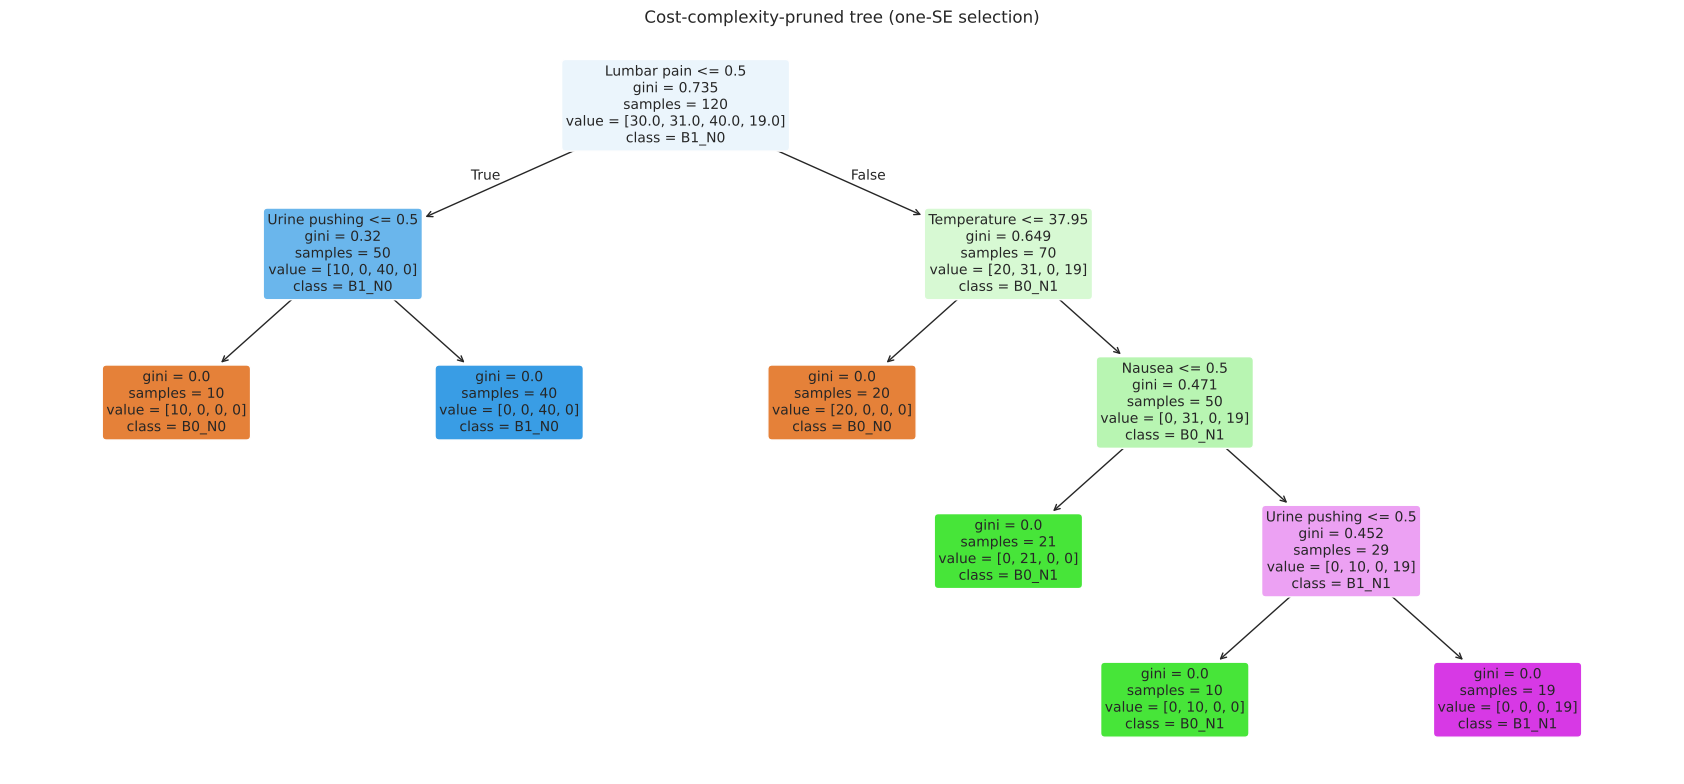

1. IF Lumbar pain = no AND Urine pushing = no THEN B0_N0 (training n=10).
2. IF Lumbar pain = no AND Urine pushing = yes THEN B1_N0 (training n=40).
3. IF Lumbar pain = yes AND Temperature <= 37.95 C THEN B0_N0 (training n=20).
4. IF Lumbar pain = yes AND Temperature > 37.95 C AND Nausea = no THEN B0_N1 (training n=21).
5. IF Lumbar pain = yes AND Temperature > 37.95 C AND Nausea = yes AND Urine pushing = no THEN B0_N1 (training n=10).
6. IF Lumbar pain = yes AND Temperature > 37.95 C AND Nausea = yes AND Urine pushing = yes THEN B1_N1 (training n=19).
Best mean CV accuracy = 0.9917; one-SE acceptance threshold = 0.9833.
Pruning removed 0 leaves.


In [6]:
tree_cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
tree_alphas = np.r_[0., np.logspace(-4,0,100)]
tree_scores = np.array([cross_val_score(DecisionTreeClassifier(ccp_alpha=a, random_state=SEED),
                                       X_diag,y_diag,cv=tree_cv,scoring='accuracy') for a in tree_alphas])
tree_means = tree_scores.mean(axis=1)
tree_se = tree_scores.std(axis=1,ddof=1)/np.sqrt(5)
best_i = np.argmax(tree_means)
threshold = tree_means[best_i]-tree_se[best_i]
chosen_i = np.flatnonzero(tree_means >= threshold-1e-12)[-1]
pruned_tree = DecisionTreeClassifier(ccp_alpha=tree_alphas[chosen_i],random_state=SEED).fit(X_diag,y_diag)
display(pd.DataFrame({'Model':['Full','Pruned'], 'Alpha':[0,tree_alphas[chosen_i]],
 'CV accuracy':[tree_means[0],tree_means[chosen_i]],'CV SE':[tree_se[0],tree_se[chosen_i]],
 'Depth':[full_tree.get_depth(),pruned_tree.get_depth()], 'Leaves':[full_tree.get_n_leaves(),pruned_tree.get_n_leaves()],
 'Training accuracy':[full_tree.score(X_diag,y_diag),pruned_tree.score(X_diag,y_diag)]}))
fig,ax=plt.subplots(figsize=(17,8))
plot_tree(pruned_tree, feature_names=feature_names,class_names=pruned_tree.classes_,filled=True,rounded=True,fontsize=10,ax=ax)
ax.set_title('Cost-complexity-pruned tree (one-SE selection)');plt.tight_layout();plt.show()
pruned_rules = decision_rules(pruned_tree)
print(f'Best mean CV accuracy = {tree_means[best_i]:.4f}; one-SE acceptance threshold = {threshold:.4f}.')
print('Pruning removed',full_tree.get_n_leaves()-pruned_tree.get_n_leaves(),'leaves.')

The four-leaf alternative uses `ccp_alpha = 0.098167`, with training accuracy of 84.17% and descriptive cross-validation accuracy of 85.83%. Its rules are shorter, but the six-leaf tree provides better joint-label prediction. The four-leaf candidate comes from the full-data pruning path, so its cross-validation score is descriptive rather than an independent validation estimate.

,Alpha,Leaves,Depth,Training accuracy
0,0.000000,6,4,1.000000
1,0.098167,4,2,0.841667
2,0.133333,3,2,0.758333
3,0.182000,2,1,0.591667
4,0.222917,1,0,0.333333


Compact alternative: alpha=0.09816667, leaves=4, training accuracy=0.8417, descriptive CV accuracy=0.8583


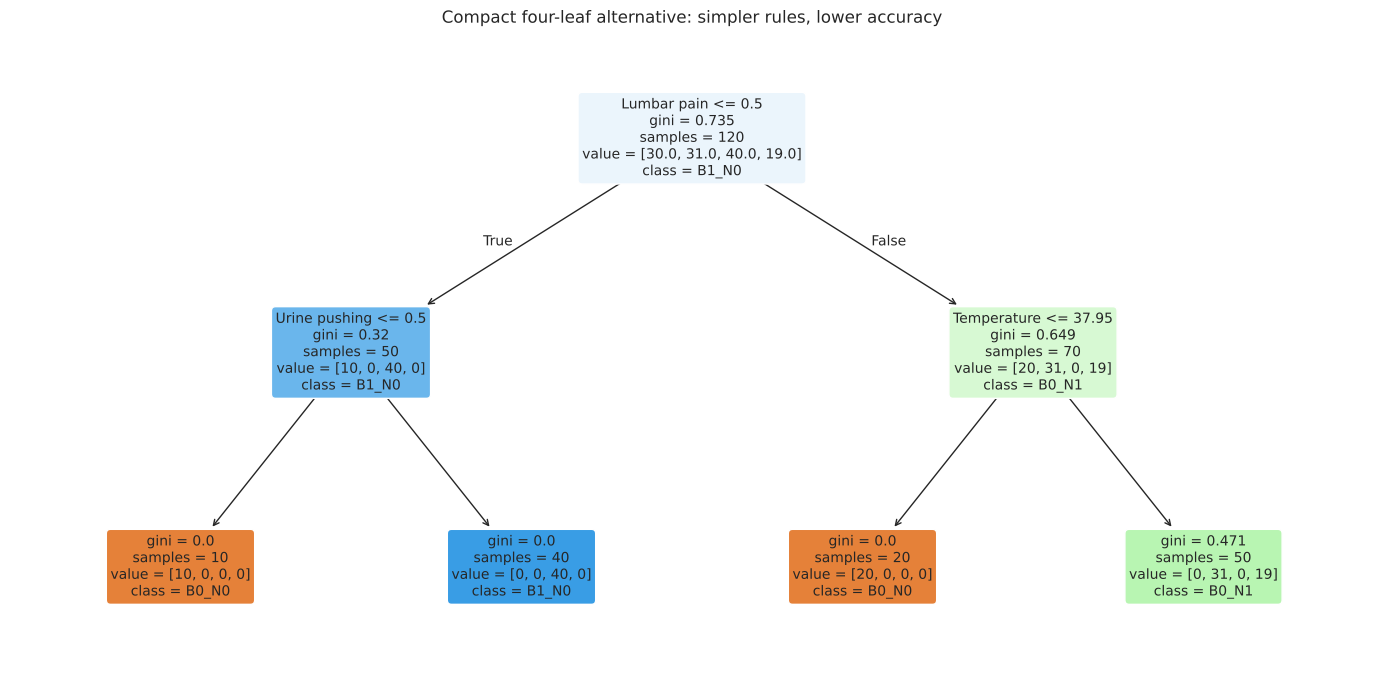

1. IF Lumbar pain = no AND Urine pushing = no THEN B0_N0 (training n=10).
2. IF Lumbar pain = no AND Urine pushing = yes THEN B1_N0 (training n=40).
3. IF Lumbar pain = yes AND Temperature <= 37.95 C THEN B0_N0 (training n=20).
4. IF Lumbar pain = yes AND Temperature > 37.95 C THEN B0_N1 (training n=50).


In [7]:
path = full_tree.cost_complexity_pruning_path(X_diag,y_diag)
path_rows=[]
for a in path.ccp_alphas:
    model=DecisionTreeClassifier(ccp_alpha=float(a),random_state=SEED).fit(X_diag,y_diag)
    path_rows.append({'Alpha':a,'Leaves':model.get_n_leaves(),'Depth':model.get_depth(),
                      'Training accuracy':model.score(X_diag,y_diag)})
display(pd.DataFrame(path_rows))
compact_alpha=float(path.ccp_alphas[1])
compact_tree=DecisionTreeClassifier(ccp_alpha=compact_alpha,random_state=SEED).fit(X_diag,y_diag)
compact_cv=cross_val_score(compact_tree,X_diag,y_diag,
    cv=StratifiedKFold(5,shuffle=True,random_state=SEED),scoring='accuracy')
print(f'Compact alternative: alpha={compact_alpha:.8f}, leaves={compact_tree.get_n_leaves()}, '
      f'training accuracy={compact_tree.score(X_diag,y_diag):.4f}, descriptive CV accuracy={compact_cv.mean():.4f}')
fig,ax=plt.subplots(figsize=(14,7))
plot_tree(compact_tree,feature_names=feature_names,class_names=compact_tree.classes_,
          filled=True,rounded=True,fontsize=10,ax=ax)
ax.set_title('Compact four-leaf alternative: simpler rules, lower accuracy')
plt.tight_layout();plt.show()
compact_rules=decision_rules(compact_tree)

### Label Powerset vs. Binary Relevance
The footnote asks whether label powerset is the more relevant approach. For comparison, binary relevance fits one tree per diagnosis. Both approaches use the same stratified five folds.

,Depth,Leaves,CV accuracy,Training accuracy
Model,,,,
BR: Bladder inflammation,3.0,4,1.000000,1.0
BR: Nephritis,2.0,3,1.000000,1.0
BR: both labels combined,NaN,7,1.000000,NaN
Label powerset (joint tree),4.0,6,0.991667,1.0


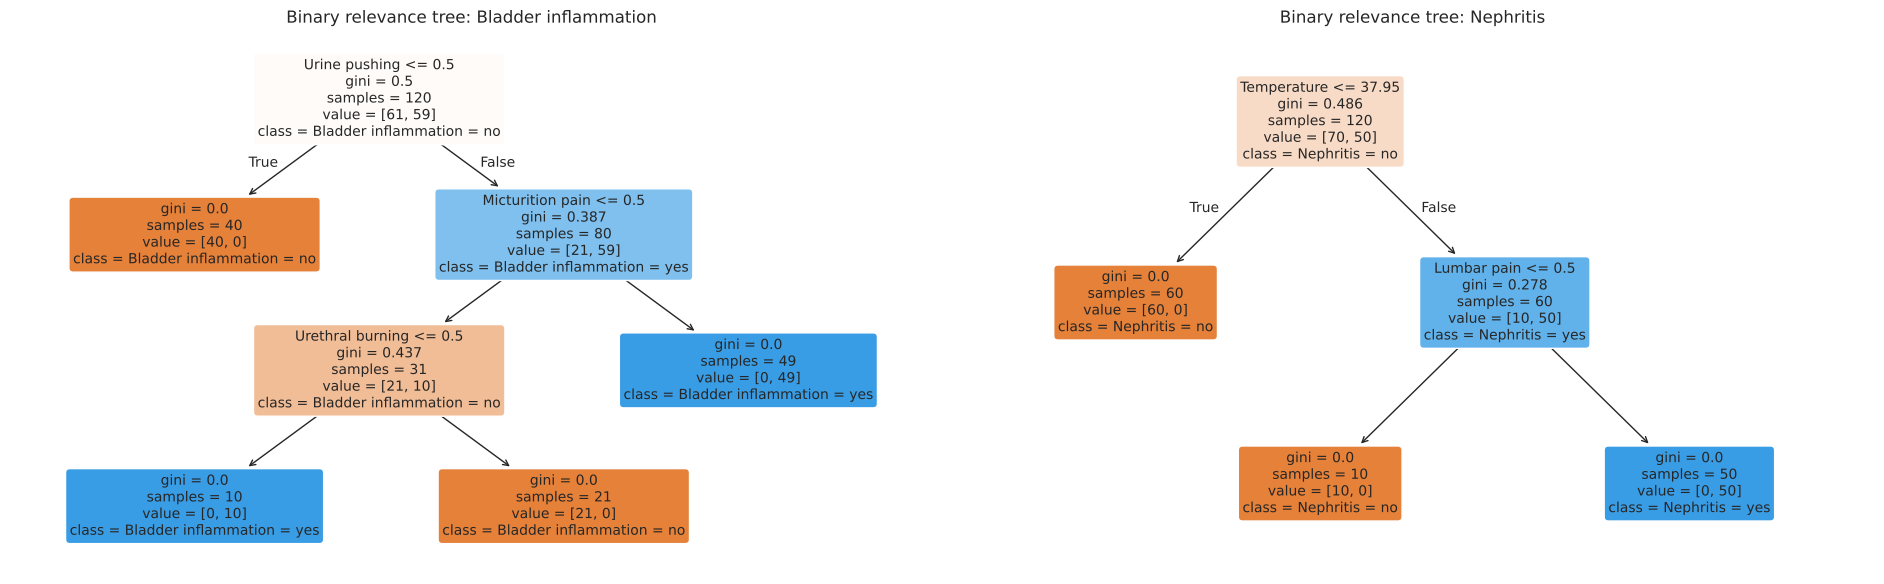


Bladder inflammation:
1. IF Urine pushing = no THEN Bladder inflammation = no (training n=40).
2. IF Urine pushing = yes AND Micturition pain = no AND Urethral burning = no THEN Bladder inflammation = yes (training n=10).
3. IF Urine pushing = yes AND Micturition pain = no AND Urethral burning = yes THEN Bladder inflammation = no (training n=21).
4. IF Urine pushing = yes AND Micturition pain = yes THEN Bladder inflammation = yes (training n=49).

Nephritis:
1. IF Temperature <= 37.95 C THEN Nephritis = no (training n=60).
2. IF Temperature > 37.95 C AND Lumbar pain = no THEN Nephritis = no (training n=10).
3. IF Temperature > 37.95 C AND Lumbar pain = yes THEN Nephritis = yes (training n=50).


In [8]:
br_folds = list(StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED).split(X_diag, y_diag))
br_trees, br_rows, br_cv_pred = {}, [], {}
for label in ['Bladder inflammation', 'Nephritis']:
    y_label = label + ' = ' + diagnosis[label]
    tree = DecisionTreeClassifier(random_state=SEED).fit(X_diag, y_label)
    br_trees[label] = tree
    acc = cross_val_score(DecisionTreeClassifier(random_state=SEED), X_diag, y_label, cv=br_folds, scoring='accuracy')
    br_cv_pred[label] = cross_val_predict(DecisionTreeClassifier(random_state=SEED), X_diag, y_label, cv=br_folds)
    br_rows.append({'Model': f'BR: {label}', 'Depth': tree.get_depth(), 'Leaves': tree.get_n_leaves(),
                    'CV accuracy': acc.mean(), 'Training accuracy': tree.score(X_diag, y_label)})
joint_br = pd.Series(br_cv_pred['Bladder inflammation']).str.endswith('yes').map({True:'B1', False:'B0'}) + '_' + \
           pd.Series(br_cv_pred['Nephritis']).str.endswith('yes').map({True:'N1', False:'N0'})
lp_cv = cross_val_score(DecisionTreeClassifier(random_state=SEED), X_diag, y_diag, cv=br_folds, scoring='accuracy')
br_rows.append({'Model': 'BR: both labels combined', 'Depth': np.nan,
                'Leaves': sum(t.get_n_leaves() for t in br_trees.values()),
                'CV accuracy': (joint_br.to_numpy() == y_diag.to_numpy()).mean(), 'Training accuracy': np.nan})
br_rows.append({'Model': 'Label powerset (joint tree)', 'Depth': full_tree.get_depth(), 'Leaves': full_tree.get_n_leaves(),
                'CV accuracy': lp_cv.mean(), 'Training accuracy': full_tree.score(X_diag, y_diag)})
display(pd.DataFrame(br_rows).set_index('Model'))
fig, axes = plt.subplots(1, 2, figsize=(19, 6))
for ax, (label, tree) in zip(axes, br_trees.items()):
    plot_tree(tree, feature_names=feature_names, class_names=tree.classes_, filled=True, rounded=True, fontsize=10, ax=ax)
    ax.set_title(f'Binary relevance tree: {label}')
plt.tight_layout(); plt.show()
for label, tree in br_trees.items():
    print(f'\n{label}:')
    decision_rules(tree)

**Is label powerset the more relevant approach?** Not necessarily for this data set. Label powerset models the joint outcome directly and can capture dependence between the two diagnoses, which matters when the labels are strongly related or when the joint diagnosis is itself the target.

Here, however, the two diagnoses depend on different symptoms. Bladder inflammation depends on urine pushing, micturition pain, and urethral burning. Nephritis depends on a temperature above 37.95 C together with lumbar pain. Binary relevance therefore produces two small trees (4 and 3 leaves, depths 3 and 2) with 100% cross-validated accuracy for each label and for the combined joint prediction. The label powerset tree reaches 99.17%, needs depth four, and mixes both diagnoses in each path.

Each binary relevance rule refers to one disease, so the rules are easier to read and to check against clinical knowledge. On interpretability, binary relevance is the better choice for this data; label powerset remains reasonable when the joint outcome itself is of interest.

## 2. The LASSO and Boosting for Regression
### 2(a)–(b). Data Preparation
The response is `ViolentCrimesPerPop`. Removing `state`, `county`, `community`, `communityname`, and `fold` leaves 122 predictors. The training set contains the first 1,495 rows, and the test set contains the remaining 499 rows.

Missing values are replaced with training medians. Imputation, standardization, and PCA are fitted separately within each training fold during cross-validation.

In [9]:
columns = re.findall(r'^@attribute\s+(\S+)', (DATA/'communities.names').read_text(), re.MULTILINE)
crime = pd.read_csv(DATA/'communities.data',header=None,names=columns,na_values='?')
nonpredictive = ['state','county','community','communityname','fold']
target = 'ViolentCrimesPerPop'
X = crime.drop(columns=nonpredictive+[target]).astype(float)
y = crime[target].astype(float)
X_train,X_test = X.iloc[:1495].copy(),X.iloc[1495:].copy()
y_train,y_test = y.iloc[:1495].copy(),y.iloc[1495:].copy()
assert crime.shape == (1994,128) and X_train.shape == (1495,122) and X_test.shape == (499,122)
assert y.notna().all() and not X_train.isna().all().any()
imputer = SimpleImputer(strategy='median')
X_train_imp = pd.DataFrame(imputer.fit_transform(X_train),columns=X.columns,index=X_train.index)
X_test_imp = pd.DataFrame(imputer.transform(X_test),columns=X.columns,index=X_test.index)
print('Training:',X_train.shape,'Test:',X_test.shape)
missing = pd.DataFrame({'Train missing':X_train.isna().sum(),'Train missing fraction':X_train.isna().mean()})
display(missing.loc[missing['Train missing']>0].sort_values('Train missing',ascending=False))
cv = KFold(n_splits=5,shuffle=True,random_state=SEED)
results=[]
def record(name, model, cv_mse=np.nan, tuning='None'):
    pred = model.predict(X_test)
    row = {'Model':name,'CV MSE':cv_mse,'Test MSE':mean_squared_error(y_test,pred),
           'Test RMSE':np.sqrt(mean_squared_error(y_test,pred)), 'Test MAE':mean_absolute_error(y_test,pred),
           'Test R2':r2_score(y_test,pred),'Tuning':tuning}
    results.append(row)
    display(pd.DataFrame([row]).set_index('Model'))
    return pred
baseline = np.repeat(y_train.mean(),len(y_test))
print(f'Training-mean baseline test MSE: {mean_squared_error(y_test,baseline):.6f}')

Training: (1495, 122) Test: (499, 122)


,Train missing,Train missing fraction
LemasSwornFT,1256,0.840134
LemasSwFTPerPop,1256,0.840134
LemasSwFTFieldOps,1256,0.840134
LemasTotalReq,1256,0.840134
LemasSwFTFieldPerPop,1256,0.840134
LemasTotReqPerPop,1256,0.840134
PolicReqPerOffic,1256,0.840134
OfficAssgnDrugUnits,1256,0.840134
PolicPerPop,1256,0.840134
RacialMatchCommPol,1256,0.840134


Training-mean baseline test MSE: 0.047666


### 2(c). Feature Correlation Matrix
The matrix shows Pearson correlations among the 122 predictors after training-set median imputation. Strong correlations indicate substantial overlap among several predictors.

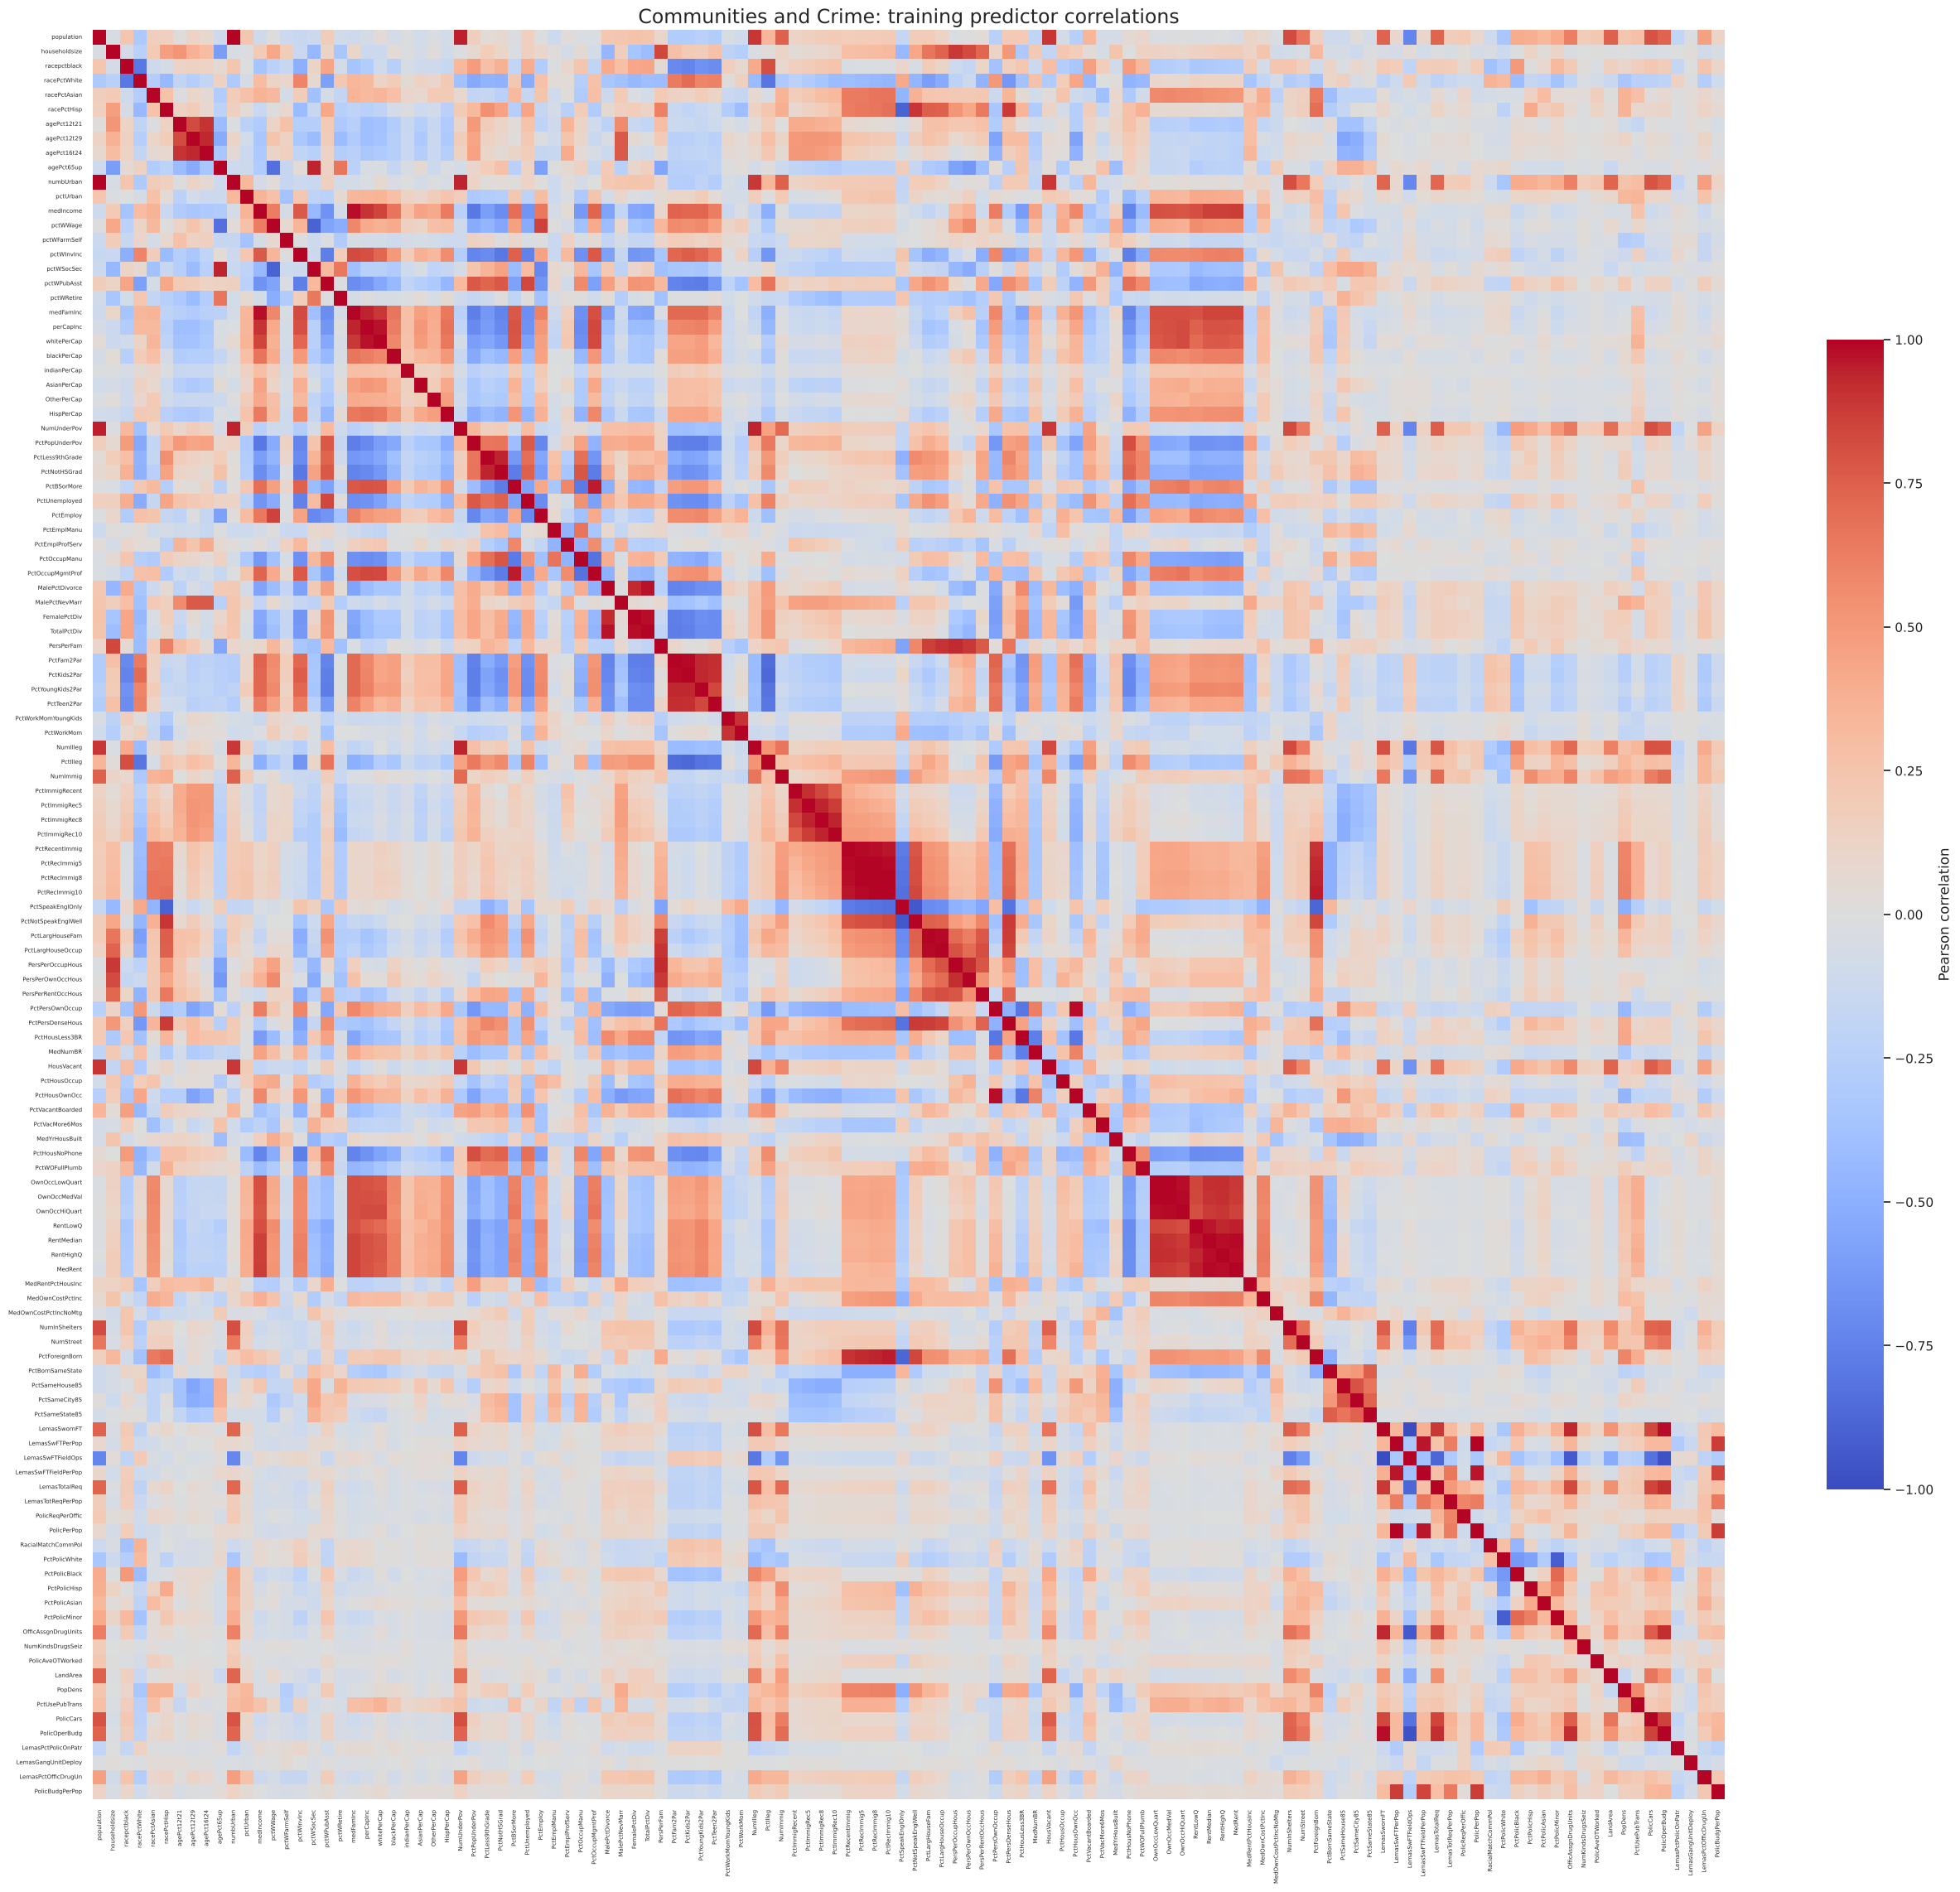

,,Correlation
LemasSwFTPerPop,PolicPerPop,1.000000
PctRecImmig8,PctRecImmig10,0.995561
OwnOccLowQuart,OwnOccMedVal,0.994692
LemasSwornFT,LemasSwFTFieldOps,-0.994505
population,numbUrban,0.993613
PctRecImmig5,PctRecImmig8,0.992735
OwnOccMedVal,OwnOccHiQuart,0.991559
PctRecentImmig,PctRecImmig5,0.989361
RentMedian,MedRent,0.988780
PctFam2Par,PctKids2Par,0.985623


In [10]:
corr = X_train_imp.corr()
fig,ax=plt.subplots(figsize=(26,23))
sns.heatmap(corr,cmap='coolwarm',vmin=-1,vmax=1,center=0,xticklabels=True,yticklabels=True,
            cbar_kws={'label':'Pearson correlation','shrink':0.65},ax=ax)
ax.tick_params(axis='both',labelsize=5)
ax.set_title('Communities and Crime: training predictor correlations',fontsize=17)
plt.tight_layout();plt.show()
upper=corr.where(np.triu(np.ones(corr.shape),k=1).astype(bool)).stack()
display(upper.reindex(upper.abs().sort_values(ascending=False).index).head(15).rename('Correlation').to_frame())

### 2(d). Coefficient of Variation
For each predictor, `CV = sample standard deviation / sample mean`, using `ddof=1` on the imputed training set. All 122 values are reported below. CV measures relative dispersion, not predictive importance; its interpretation also depends on the variables' normalization.

In [11]:
feature_cv = pd.DataFrame({'Mean':X_train_imp.mean(),'Sample SD':X_train_imp.std(ddof=1)})
feature_cv['CV'] = feature_cv['Sample SD']/feature_cv['Mean'].replace(0,np.nan)
feature_cv = feature_cv.sort_values('CV',ascending=False)
display(feature_cv)
print('Features reported:',len(feature_cv),'| Undefined CVs:',feature_cv['CV'].isna().sum())

,Mean,Sample SD,CV
PctPolicAsian,0.016254,0.089838,5.527059
NumStreet,0.022983,0.098665,4.292923
NumInShelters,0.029599,0.102736,3.470952
NumIlleg,0.037204,0.113806,3.058964
NumImmig,0.030595,0.089541,2.926635
LemasPctOfficDrugUn,0.093304,0.238201,2.552946
NumUnderPov,0.056849,0.133167,2.342443
LemasSwornFT,0.028749,0.064629,2.248042
population,0.058167,0.130359,2.241105
numbUrban,0.064649,0.131784,2.038461


Features reported: 122 | Undefined CVs: 0


### 2(e). Highest-CV Features
The 11 predictors with the highest CV are shown below, with scatter plots against the response and box plots of their distributions.

,Mean,Sample SD,CV
PctPolicAsian,0.016254,0.089838,5.527059
NumStreet,0.022983,0.098665,4.292923
NumInShelters,0.029599,0.102736,3.470952
NumIlleg,0.037204,0.113806,3.058964
NumImmig,0.030595,0.089541,2.926635
LemasPctOfficDrugUn,0.093304,0.238201,2.552946
NumUnderPov,0.056849,0.133167,2.342443
LemasSwornFT,0.028749,0.064629,2.248042
population,0.058167,0.130359,2.241105
numbUrban,0.064649,0.131784,2.038461


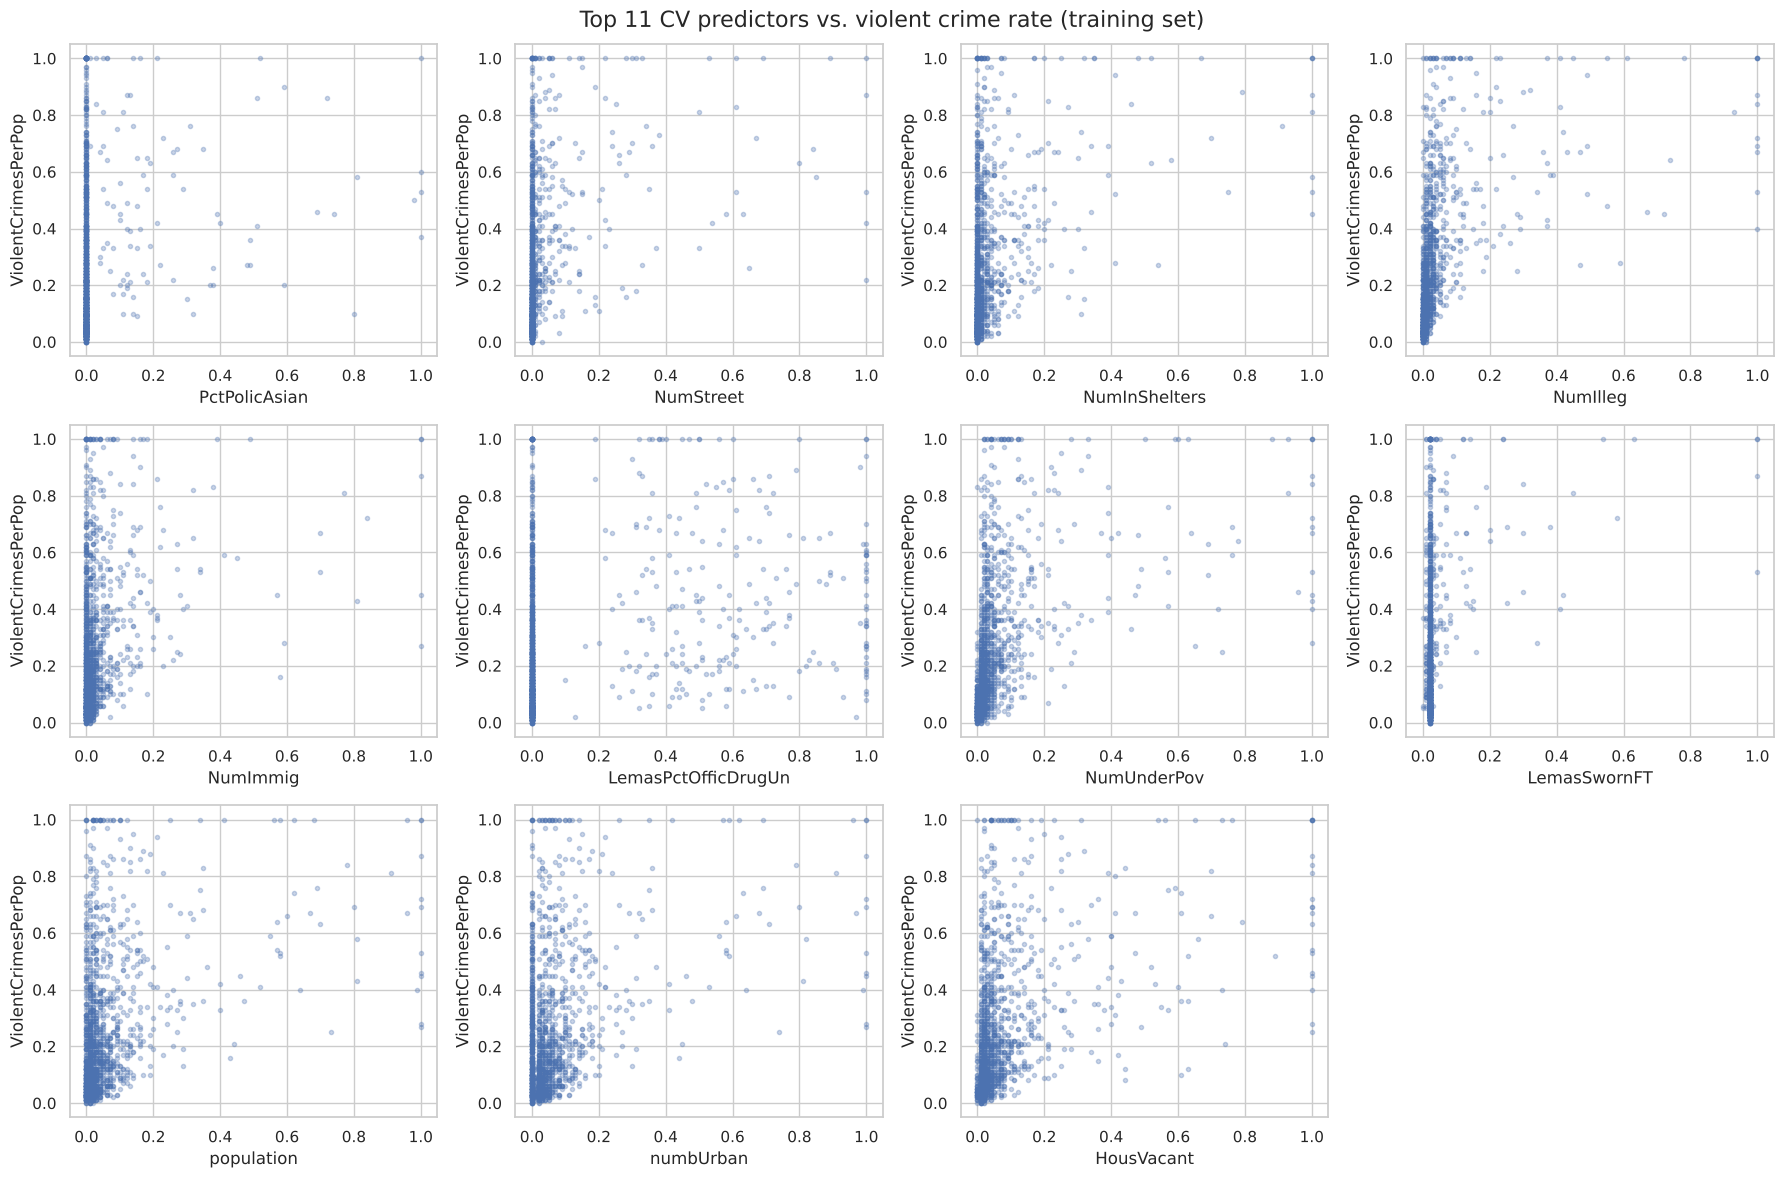

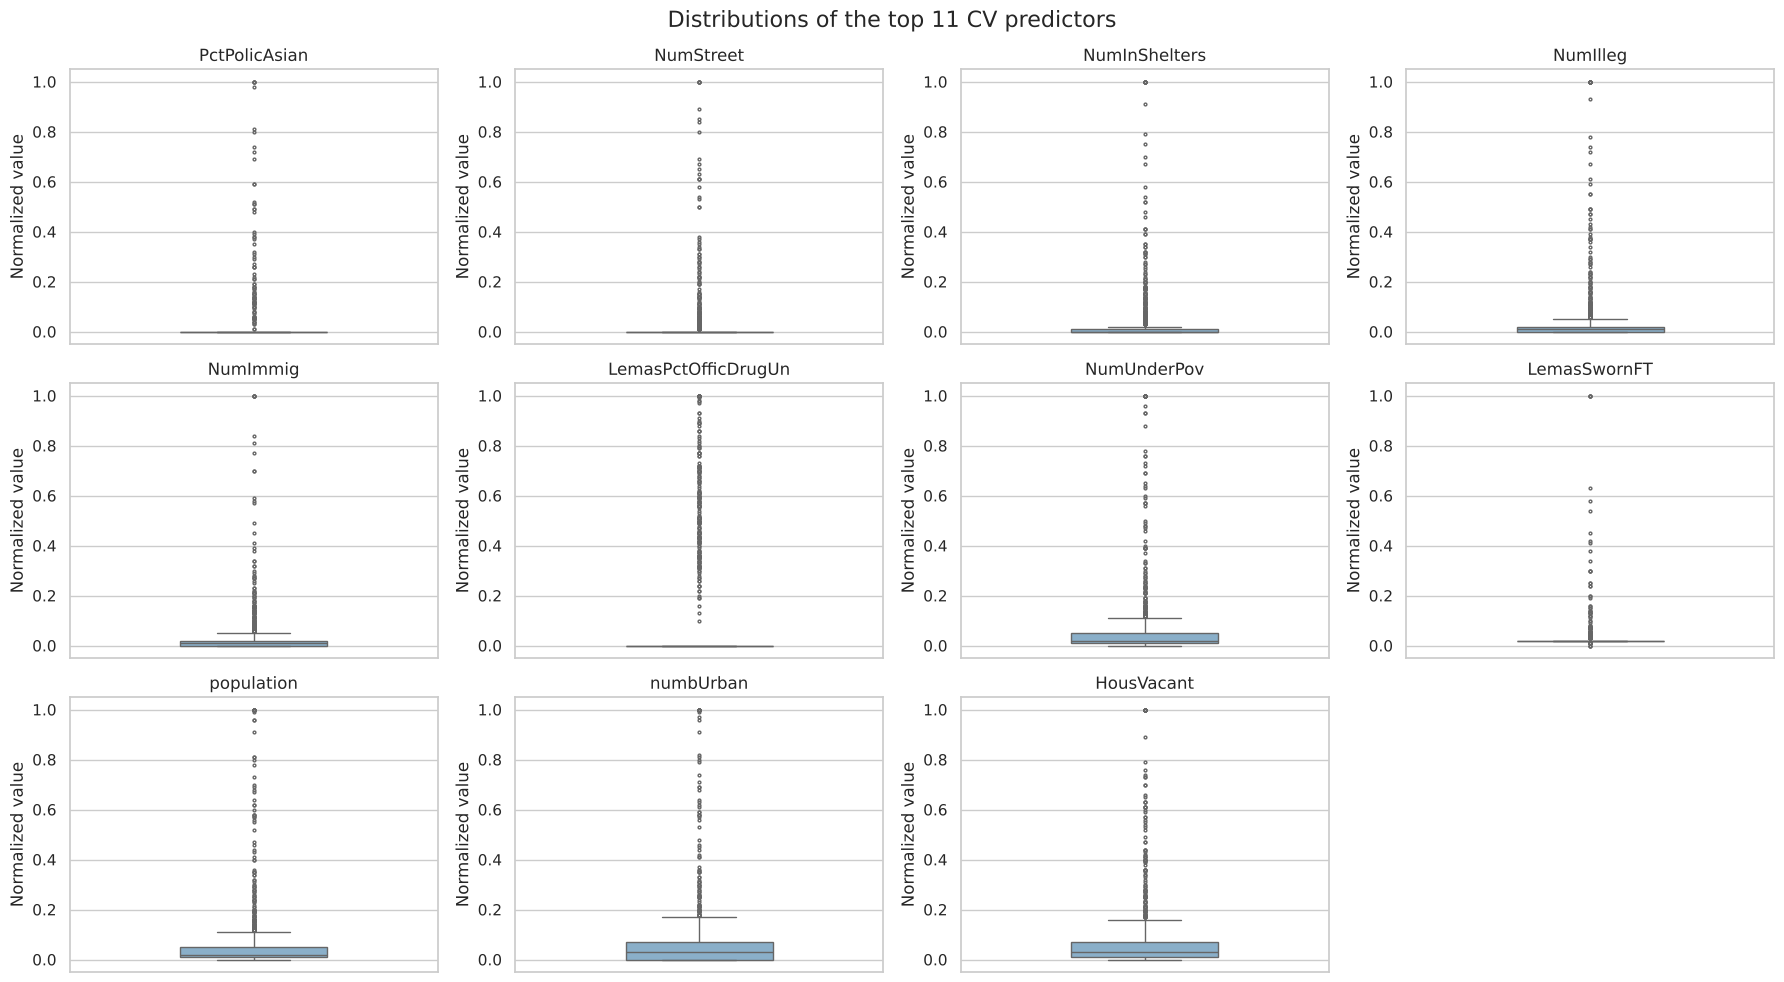

In [12]:
top_features = feature_cv['CV'].dropna().head(int(np.floor(np.sqrt(128)))).index.tolist()
display(feature_cv.loc[top_features])
fig,axes=plt.subplots(3,4,figsize=(18,12))
for ax,col in zip(axes.flat,top_features):
    ax.scatter(X_train_imp[col],y_train,s=9,alpha=0.3)
    ax.set(xlabel=col,ylabel=target)
for ax in list(axes.flat)[len(top_features):]: ax.axis('off')
fig.suptitle('Top 11 CV predictors vs. violent crime rate (training set)',fontsize=16)
plt.tight_layout();plt.show()
fig,axes=plt.subplots(3,4,figsize=(18,10))
for ax,col in zip(axes.flat,top_features):
    sns.boxplot(y=X_train_imp[col],ax=ax,color='#80b1d3',width=0.4,fliersize=2)
    ax.set_title(col);ax.set_ylabel('Normalized value')
for ax in list(axes.flat)[len(top_features):]: ax.axis('off')
fig.suptitle('Distributions of the top 11 CV predictors',fontsize=16)
plt.tight_layout();plt.show()

No. Scatter plots can suggest associations, outliers, or nonlinear patterns, but cannot establish statistical significance. High CV indicates high relative dispersion, not a strong association with violent crime. Box plots summarize marginal distributions and cannot establish significance either. Formal inference requires a specified model, uncertainty estimates, and consideration of correlated predictors and multiple comparisons. Median imputation can also create concentrations of observations.

### 2(f). Ordinary Least Squares
Using all 122 predictors and an intercept, the test MSE is **0.017966**.

In [13]:
ols = Pipeline([('imputer',SimpleImputer(strategy='median')),('model',LinearRegression())])
ols_cv = -cross_val_score(ols,X_train,y_train,cv=cv,scoring='neg_mean_squared_error').mean()
ols.fit(X_train,y_train)
ols_pred = record('OLS',ols,ols_cv)

,CV MSE,Test MSE,Test RMSE,Test MAE,Test R2,Tuning
Model,,,,,,
OLS,0.020801,0.017966,0.134038,0.096265,0.622204,None


### 2(g). Ridge Regression
Five-fold cross-validation selects **λ = 146.77993** for standardized predictors. The test MSE is **0.017353**. The objective is `RSS + λ × sum(beta²)`.

In [14]:
ridge = GridSearchCV(Pipeline([('imputer',SimpleImputer(strategy='median')),('scaler',StandardScaler()),('model',Ridge())]),
    {'model__alpha':np.logspace(-4,6,61)},cv=cv,scoring='neg_mean_squared_error',n_jobs=1)
ridge.fit(X_train,y_train)
ridge_pred = record('Ridge (standardized)',ridge,-ridge.best_score_,f"lambda={ridge.best_params_['model__alpha']:.8g}")
print('Optimum is on grid boundary:',ridge.best_params_['model__alpha'] in [1e-4,1e6])

,CV MSE,Test MSE,Test RMSE,Test MAE,Test R2,Tuning
Model,,,,,,
Ridge (standardized),0.019737,0.017353,0.131731,0.094258,0.635099,lambda=146.77993


Optimum is on grid boundary: False


### 2(h). LASSO Regression
For the original normalized predictors, cross-validation selects **λ = 0.00013335214**, with test MSE **0.017604**. For standardized predictors, it selects **λ = 0.00056234133**, with test MSE **0.017748**.

The objective is `RSS/(2n) + λ × sum(abs(beta))`. Variables with nonzero coefficients are listed below for each model.

In [15]:
lassos={}
for standardize in [False,True]:
    steps=[('imputer',SimpleImputer(strategy='median'))]
    if standardize: steps.append(('scaler',StandardScaler()))
    steps.append(('model',Lasso(max_iter=100000,tol=1e-5)))
    search=GridSearchCV(Pipeline(steps),{'model__alpha':np.logspace(-5,0,41)},cv=cv,
                        scoring='neg_mean_squared_error',n_jobs=1)
    search.fit(X_train,y_train)
    name='LASSO (standardized)' if standardize else 'LASSO (original normalized)'
    lassos[name]=search
    record(name,search,-search.best_score_,f"lambda={search.best_params_['model__alpha']:.8g}")
    coef=pd.Series(search.best_estimator_.named_steps['model'].coef_,index=X.columns)
    selected=coef[coef!=0].sort_values(key=abs,ascending=False)
    print(f'{name}: {len(selected)} selected variables; alpha={search.best_params_["model__alpha"]:.8g}')
    display(selected.rename('Coefficient').to_frame())
    print('Selected variables:',', '.join(selected.index))
    print('Optimum is on grid boundary:',search.best_params_['model__alpha'] in [1e-5,1.0])

,CV MSE,Test MSE,Test RMSE,Test MAE,Test R2,Tuning
Model,,,,,,
LASSO (original normalized),0.019524,0.017604,0.132678,0.094324,0.629831,lambda=0.00013335214


LASSO (original normalized): 76 selected variables; alpha=0.00013335214


,Coefficient
racepctblack,0.266506
agePct12t29,-0.233105
PctPersDenseHous,0.203820
PctKids2Par,-0.198172
NumStreet,0.155708
RentLowQ,-0.150295
MedRent,0.146509
PctPopUnderPov,-0.134525
PctWorkMom,-0.125486
PctEmploy,0.120955


Selected variables: racepctblack, agePct12t29, PctPersDenseHous, PctKids2Par, NumStreet, RentLowQ, MedRent, PctPopUnderPov, PctWorkMom, PctEmploy, HousVacant, MalePctNevMarr, MalePctDivorce, pctWRetire, PctIlleg, pctWInvInc, MedRentPctHousInc, PolicReqPerOffic, MedOwnCostPctIncNoMtg, NumImmig, pctWWage, PctVacantBoarded, NumIlleg, LemasSwFTFieldPerPop, FemalePctDiv, PctNotSpeakEnglWell, PctHousOccup, PctVacMore6Mos, whitePerCap, agePct12t21, NumInShelters, PctHousLess3BR, PctPersOwnOccup, PctForeignBorn, pctWSocSec, PctLargHouseOccup, PctYoungKids2Par, PctUsePubTrans, pctUrban, pctWPubAsst, LemasGangUnitDeploy, PctRecImmig10, indianPerCap, AsianPerCap, NumKindsDrugsSeiz, LandArea, PctSameCity85, pctWFarmSelf, OtherPerCap, PctWOFullPlumb, PctHousNoPhone, PctPolicAsian, HispPerCap, blackPerCap, PersPerOccupHous, PctLess9thGrade, RacialMatchCommPol, MedYrHousBuilt, LemasPctPolicOnPatr, racePctAsian, PctEmplManu, PopDens, MedOwnCostPctInc, PctPolicBlack, PctPolicHisp, PctOccupManu, PolicCa

,CV MSE,Test MSE,Test RMSE,Test MAE,Test R2,Tuning
Model,,,,,,
LASSO (standardized),0.019668,0.017748,0.133222,0.094891,0.626792,lambda=0.00056234133


LASSO (standardized): 75 selected variables; alpha=0.00056234133


,Coefficient
racepctblack,0.068266
agePct12t29,-0.046063
PctPersDenseHous,0.045000
PctKids2Par,-0.040545
MedRent,0.032825
RentLowQ,-0.032550
PctPopUnderPov,-0.030899
PctEmploy,0.027019
MalePctNevMarr,0.027005
PctIlleg,0.023422


Selected variables: racepctblack, agePct12t29, PctPersDenseHous, PctKids2Par, MedRent, RentLowQ, PctPopUnderPov, PctEmploy, MalePctNevMarr, PctIlleg, PctWorkMom, pctWInvInc, MalePctDivorce, pctWRetire, HousVacant, NumStreet, pctUrban, FemalePctDiv, MedRentPctHousInc, PctVacantBoarded, pctWWage, PctNotSpeakEnglWell, MedOwnCostPctIncNoMtg, PctLargHouseOccup, agePct12t21, PersPerOccupHous, PctPersOwnOccup, PctHousLess3BR, PctHousOccup, NumImmig, PctVacMore6Mos, NumIlleg, pctWSocSec, PctUsePubTrans, whitePerCap, PolicReqPerOffic, PctForeignBorn, PctRecImmig10, NumInShelters, pctWPubAsst, PolicCars, PctYoungKids2Par, LemasSwFTFieldPerPop, LemasGangUnitDeploy, LemasTotalReq, AsianPerCap, LandArea, PctWOFullPlumb, indianPerCap, pctWFarmSelf, HispPerCap, PctHousNoPhone, PctLess9thGrade, OtherPerCap, MedOwnCostPctInc, blackPerCap, PopDens, PctSameCity85, NumKindsDrugsSeiz, PctPolicBlack, MedYrHousBuilt, RacialMatchCommPol, PctPolicHisp, OfficAssgnDrugUnits, OwnOccLowQuart, racePctAsian, PctTeen

In [16]:
raw_mse=next(r['Test MSE'] for r in results if r['Model']=='LASSO (original normalized)')
std_mse=next(r['Test MSE'] for r in results if r['Model']=='LASSO (standardized)')
better='standardized' if std_mse<raw_mse else 'original normalized'
display(Markdown(f'**Comparison:** Test MSE is **{raw_mse:.6f}** without additional standardization and **{std_mse:.6f}** after standardization; the **{better}** model has lower test MSE in this split. Although the supplied predictors lie in [0,1], their standard deviations differ, so standardization changes the relative penalty and may change both selection and prediction. This comparison does not imply that standardization always improves test performance.'))

**Comparison:** Test MSE is **0.017604** without additional standardization and **0.017748** after standardization; the **original normalized** model has lower test MSE in this split. Although the supplied predictors lie in [0,1], their standard deviations differ, so standardization changes the relative penalty and may change both selection and prediction. This comparison does not imply that standardization always improves test performance.

### 2(i). Principal Component Regression
Five-fold cross-validation over 1–122 components selects **M = 60**. The test MSE is **0.018350**. Imputation, standardization, and PCA are fitted separately within each training fold.

,CV MSE,Test MSE,Test RMSE,Test MAE,Test R2,Tuning
Model,,,,,,
PCR (standardized),0.02021,0.01835,0.13546,0.097174,0.614143,M=60


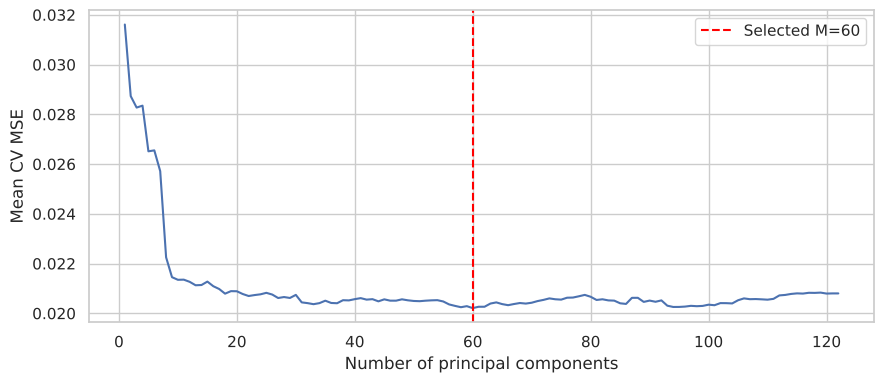

Selected components explain 98.06% of standardized training predictor variance.


In [17]:
p=X_train.shape[1]
pcr_losses=np.zeros((5,p))
for fold,(tr,va) in enumerate(cv.split(X_train)):
    imp=SimpleImputer(strategy='median')
    sc=StandardScaler()
    A=sc.fit_transform(imp.fit_transform(X_train.iloc[tr]))
    B=sc.transform(imp.transform(X_train.iloc[va]))
    pc=PCA(n_components=p,svd_solver='full').fit(A)
    T=pc.transform(A); V=pc.transform(B)
    yy=y_train.iloc[tr].to_numpy(); center=yy.mean()
    denom=(T*T).sum(axis=0)
    beta=np.divide(T.T@(yy-center),denom,out=np.zeros(p),where=denom>1e-12)
    preds=center+np.cumsum(V*beta,axis=1)
    pcr_losses[fold]=((y_train.iloc[va].to_numpy()[:,None]-preds)**2).mean(axis=0)
pcr_mean=pcr_losses.mean(axis=0)
best_M=int(np.argmin(pcr_mean)+1)
pcr=Pipeline([('imputer',SimpleImputer(strategy='median')),('scaler',StandardScaler()),
              ('pca',PCA(n_components=best_M,svd_solver='full')),('model',LinearRegression())])
pcr.fit(X_train,y_train)
pcr_pred=record('PCR (standardized)',pcr,pcr_mean[best_M-1],f'M={best_M}')
plt.figure(figsize=(9,4));plt.plot(np.arange(1,p+1),pcr_mean)
plt.axvline(best_M,color='red',linestyle='--',label=f'Selected M={best_M}')
plt.xlabel('Number of principal components');plt.ylabel('Mean CV MSE');plt.legend();plt.tight_layout();plt.show()
print('Selected components explain',f"{pcr.named_steps['pca'].explained_variance_ratio_.sum():.2%}",'of standardized training predictor variance.')

### 2(j). L1-Regularized Gradient-Boosted Trees
Five-fold cross-validation selects **α = 0.1**, with test MSE **0.016422**. The model uses 300 trees, maximum depth 3, learning rate 0.05, and `reg_lambda = 1`.

XGBoost's `gbtree` L1 penalty applies to scalar leaf weights; it does not fit a separate multivariable LASSO regression at each node.

In [18]:
xgb_alphas=np.r_[0.,np.logspace(-4,2,13)]
xgb=GridSearchCV(Pipeline([('imputer',SimpleImputer(strategy='median')),('model',XGBRegressor(
    objective='reg:squarederror',booster='gbtree',n_estimators=300,max_depth=3,learning_rate=0.05,
    subsample=1,colsample_bytree=1,reg_lambda=1,random_state=SEED,n_jobs=1,tree_method='hist'))]),
    {'model__reg_alpha':xgb_alphas},cv=cv,scoring='neg_mean_squared_error',n_jobs=1)
xgb.fit(X_train,y_train)
xgb_pred=record('XGBoost (L1)',xgb,-xgb.best_score_,f"alpha={xgb.best_params_['model__reg_alpha']:.8g}")
xgb_curve=pd.DataFrame({'Alpha':xgb.cv_results_['param_model__reg_alpha'].astype(float),
                       'CV MSE':-xgb.cv_results_['mean_test_score']})
display(xgb_curve)
print('Optimum at upper boundary:',xgb.best_params_['model__reg_alpha']==xgb_alphas[-1])

,CV MSE,Test MSE,Test RMSE,Test MAE,Test R2,Tuning
Model,,,,,,
XGBoost (L1),0.019907,0.016422,0.128148,0.088914,0.654678,alpha=0.1


,Alpha,CV MSE
0,0.000000,0.020198
1,0.000100,0.020132
2,0.000316,0.020121
3,0.001000,0.020252
4,0.003162,0.020193
5,0.010000,0.020054
6,0.031623,0.020283
7,0.100000,0.019907
8,0.316228,0.020277
9,1.000000,0.020243


Optimum at upper boundary: False


## Model Comparison
All models use the same 499 test observations and five-fold training splits. Preprocessing is fitted within each training fold. MSE is measured in squared normalized response units.

In [19]:
summary=pd.DataFrame(results).set_index('Model')
display(summary)
best_cv_name=summary['CV MSE'].idxmin()
best_test_name=summary['Test MSE'].idxmin()
display(Markdown(f'**Lowest cross-validation MSE:** {best_cv_name}. **Lowest observed test MSE:** {best_test_name}. The training-mean baseline test MSE is {mean_squared_error(y_test,baseline):.6f}. Model choice should be based on training CV, while the test comparison describes held-out performance; selecting a model repeatedly from test results would compromise that holdout.'))

,CV MSE,Test MSE,Test RMSE,Test MAE,Test R2,Tuning
Model,,,,,,
OLS,0.020801,0.017966,0.134038,0.096265,0.622204,None
Ridge (standardized),0.019737,0.017353,0.131731,0.094258,0.635099,lambda=146.77993
LASSO (original normalized),0.019524,0.017604,0.132678,0.094324,0.629831,lambda=0.00013335214
LASSO (standardized),0.019668,0.017748,0.133222,0.094891,0.626792,lambda=0.00056234133
PCR (standardized),0.020210,0.018350,0.135460,0.097174,0.614143,M=60
XGBoost (L1),0.019907,0.016422,0.128148,0.088914,0.654678,alpha=0.1


**Lowest cross-validation MSE:** LASSO (original normalized). **Lowest observed test MSE:** XGBoost (L1). The training-mean baseline test MSE is 0.047666. Model choice should be based on training CV, while the test comparison describes held-out performance; selecting a model repeatedly from test results would compromise that holdout.

Strongly correlated predictors can make individual coefficients unstable; selected variables are not automatically significant or causal. Median imputation retains all predictors but can obscure relationships for heavily missing police variables. The ordered train/test split may also produce distribution differences between the two sets.